# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Bima Satriawan | 5054251031 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                            calinski_harabasz_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [6]:
df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)
print(df.dtypes)
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   2

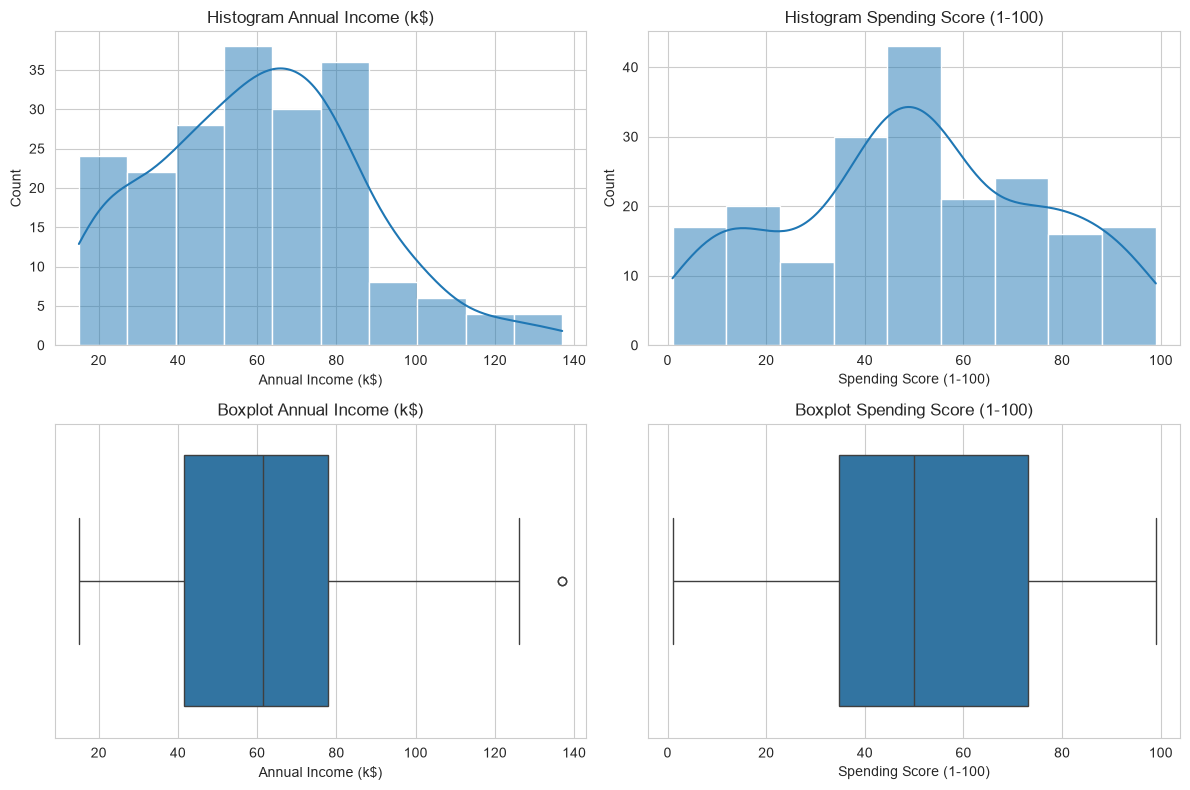

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df["Annual Income (k$)"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Histogram Annual Income (k$)")
sns.histplot(df["Spending Score (1-100)"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Histogram Spending Score (1-100)")
sns.boxplot(x=df["Annual Income (k$)"], ax=axes[1, 0])
axes[1, 0].set_title("Boxplot Annual Income (k$)")
sns.boxplot(x=df["Spending Score (1-100)"], ax=axes[1, 1])
axes[1, 1].set_title("Boxplot Spending Score (1-100)")
plt.tight_layout()
plt.show()

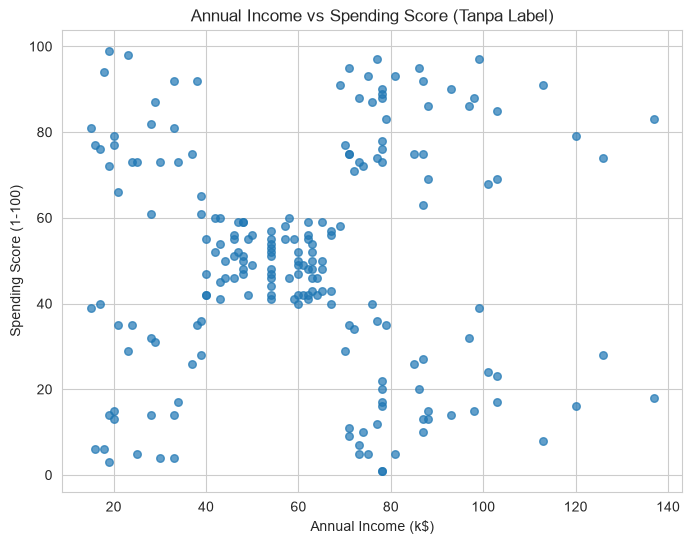

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
            s=30, alpha=0.7)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score (Tanpa Label)")
plt.show()

- Missing Value dan Duplikat: Dataset berisi 200 baris dan 5 kolom. Tidak ditemukan missing value maupun duplikat.
- Rentang: Annual Income (k$) berkisar sekitar 15-137, sedangkan Spending Score (1-100) berkisar 1-99. Distribusi pendapatan agak miring ke kanan, spending score cukup menyebar merata.
- Kelompok terpisah: Dari scatter plot terlihat pola lima kelompok yang cukup jelas: (pendapatan rendah-spending rendah), (rendah-tinggi), (menengah-menengah), (tinggi-rendah), dan (tinggi-tinggi)

# 2. Preprocessing

In [9]:
print("Missing value:", df.isnull().sum().sum())
print("Duplikat:", df.duplicated().sum())
df = df.dropna().drop_duplicates()

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
X.head()

Missing value: 0
Duplikat: 0


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [10]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index,
)
print(X_scaled.head())
print(X_scaled.describe())

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980
       Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


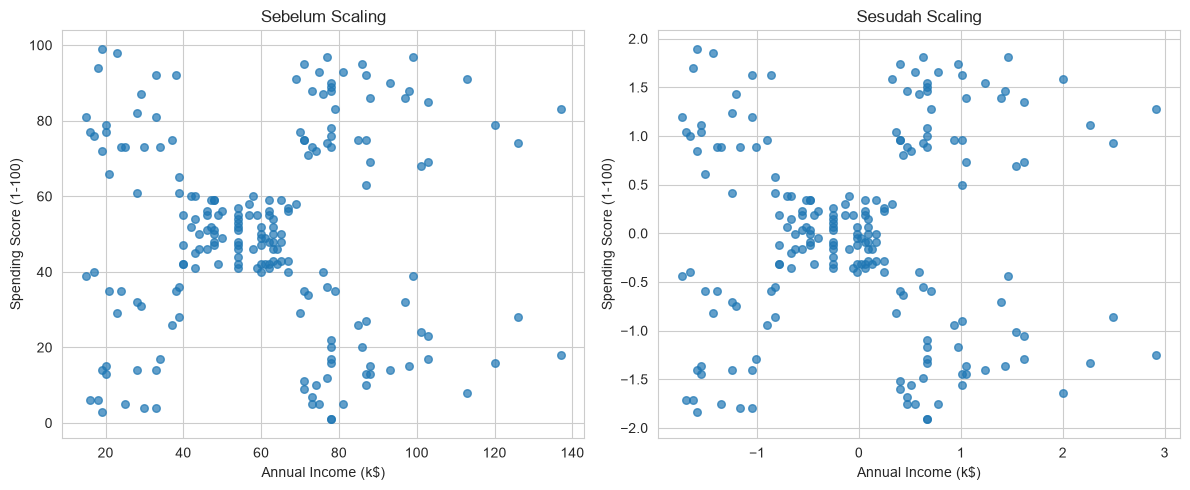

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], s=30, alpha=0.7)
axes[0].set_title("Sebelum Scaling"); axes[0].set_xlabel(X.columns[0]); axes[0].set_ylabel(X.columns[1])
axes[1].scatter(X_scaled.iloc[:, 0], X_scaled.iloc[:, 1], s=30, alpha=0.7)
axes[1].set_title("Sesudah Scaling"); axes[1].set_xlabel(X_scaled.columns[0]); axes[1].set_ylabel(X_scaled.columns[1])
plt.tight_layout(); plt.show()

Fitur yang dipakai: Annual Income (k$) dan Spending Score (1-100) karena keduanya numerik, relevan untuk segmentasi pelanggan, dan hanya dua dimensi sehingga mudah divisualisasikan. CustomerID tidak dipakai karena hanya identitas unik tanpa makna kemiripan antar pelanggan. Scaling diperlukan karena DBSCAN, BIRCH, dan GMM (jarak & kovarians) sensitif terhadap skala fitur tanpa scaling, fitur dengan rentang besar (pendapatan, ~15–137) akan mendominasi fitur dengan rentang kecil (spending, ~1–99).

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [12]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [13]:
counts = pd.Series(labels_dbscan).value_counts().sort_index()
print(counts)

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_db = int((labels_dbscan == -1).sum())
print("Jumlah cluster (tanpa noise):", n_clusters_db)
print("Jumlah noise (label -1):", n_noise_db)

-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64
Jumlah cluster (tanpa noise): 7
Jumlah noise (label -1): 35


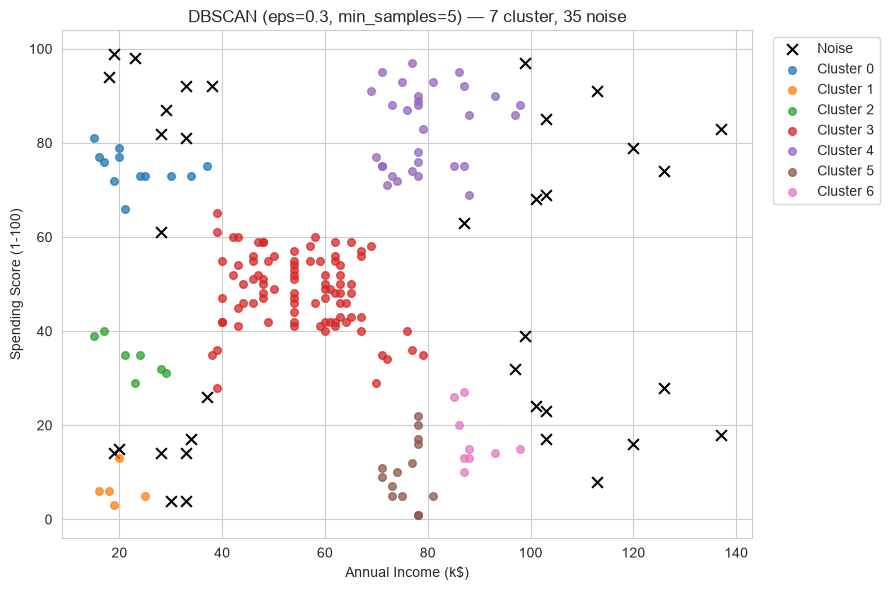

In [15]:
plt.figure(figsize=(9, 6))
for label in sorted(set(labels_dbscan)):
    mask = labels_dbscan == label
    if label == -1:
        plt.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                    c="black", marker="x", s=60, label="Noise")
    else:
        plt.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                    s=30, alpha=0.75, label=f"Cluster {label}")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"DBSCAN (eps=0.3, min_samples=5) — "
        f"{n_clusters_db} cluster, {n_noise_db} noise")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [17]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5]:
    for ms in [3, 5, 8]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_n = int((lbl == -1).sum())
        non_noise = lbl != -1
        sil = np.nan
        if n_c >= 2 and non_noise.sum() > n_c:
            sil = silhouette_score(X_scaled[non_noise], lbl[non_noise])
        rows.append({"eps": eps, "min_samples": ms,
                    "n_clusters": n_c, "n_noise": n_n,
                    "silhouette": sil})
pd.DataFrame(rows)

,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.469713
1,0.2,5,7,77,0.585613
2,0.2,8,2,116,0.602745
3,0.3,3,9,14,0.472040
4,0.3,5,7,35,0.524328
5,0.3,8,5,72,0.592556
6,0.4,3,4,10,0.395381
7,0.4,5,4,15,0.478059
8,0.4,8,5,25,0.548992
9,0.5,3,2,7,0.389247


- Kenaikan `eps`: Titik menjadi lebih mudah dijangkau tetangga, sehingga cluster yang berdekatan cenderung bergabung. Jumlah cluster turun dan noise berkurang. Pada `eps` yang terlalu besar dapat muncul satu cluster besar.
- Kenaikan `min_samples`: Syarat core point menjadi lebih ketat. Noise bertambah, cluster mengecil dan dapat terpecah.
- Kombinasi ekstrem: `eps=0.2` cenderung menghasilkan banyak noise, sedangkan `eps=0.5` dapat menyatukan banyak cluster menjadi satu cluster besar. Keduanya kurang ideal. Kombinasi `eps` sekitar 0.3 dan `min_samples=5` memberi keseimbangan antara jumlah cluster dan noise.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [18]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

In [19]:
print(pd.Series(labels_birch).value_counts().sort_index())
print("Jumlah cluster:", len(set(labels_birch)))

0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


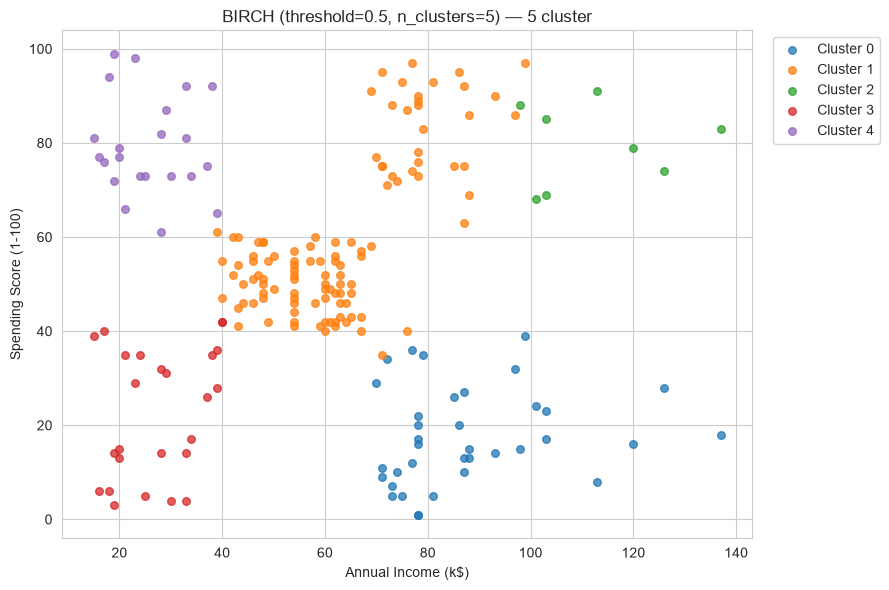

In [20]:
plt.figure(figsize=(9, 6))
for label in sorted(set(labels_birch)):
    mask = labels_birch == label
    plt.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                s=30, alpha=0.75, label=f"Cluster {label}")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"BIRCH (threshold=0.5, n_clusters=5) — {len(set(labels_birch))} cluster")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [21]:
rows = []
for thr in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=thr, n_clusters=5)
    lbl = b.fit_predict(X_scaled)
    n_c = len(set(lbl))
    sil = silhouette_score(X_scaled, lbl) if 2 <= n_c < len(lbl) else np.nan
    rows.append({"threshold": thr, "n_clusters": n_c, "silhouette": sil})
pd.DataFrame(rows)

C:\Users\Bima\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\cluster\_birch.py:725: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_clusters,silhouette
0,0.3,5,0.478062
1,0.5,5,0.414450
2,0.7,5,0.420676
3,1.0,4,0.388557


- `threshold` diperbesar: Subcluster di CF-tree lebih mudah bergabung sehingga jumlah cluster cenderung menyusut. Pada `n_clusters=5` jumlah akhir dipaksa 5, tetapi komposisi anggotanya berubah.
- BIRCH vs DBSCAN untuk outlier: BIRCH tidak punya konsep noise eksplisit. Titik jauh tetap dimasukkan ke subcluster atau cluster terdekat. DBSCAN justru menandai titik jarang sebagai -1 atau noise.
- Efek `n_clusters`: Menentukan jumlah akhir secara paksa. Tanpa `n_clusters`, BIRCH mengembalikan cluster sesuai CF-tree.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [22]:
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

In [ ]:
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"Comp {i}" for i in range(5)],
                        index=X.index)
print(proba_df.head())
uncertain = proba.max(axis=1)
print("\nRata-rata kepercayaan:", uncertain.mean().round(3))
print("5 titik paling tidak yakin:")
print(proba_df.assign(max_prob=uncertain).sort_values("max_prob").head())

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64
         Comp 0        Comp 1        Comp 2        Comp 3    Comp 4
0  1.576897e-05  1.880092e-08  9.520312e-04  5.200131e-08  0.999032
1  1.627762e-05  1.895968e-04  9.997902e-01  4.210134e-23  0.000004
2  2.213394e-19  9.526157e-19  1.225495e-12  1.862233e-04  0.999814
3  1.054448e-04  1.800877e-04  9.996937e-01  3.793901e-21  0.000021
4  6.473014e-05  3.842732e-08  1.556695e-03  4.757227e-08  0.998378

Rata-rata kepercayaan: 0.983
5 titik paling tidak yakin:
       Comp 0        Comp 1        Comp 2        Comp 3        Comp 4  \
124  0.497063  4.020399e-07  5.610367e-14  5.029323e-01  4.143026e-06   
48   0.611381  4.208143e-06  2.609859e-04  6.865689e-06  3.883471e-01   
49   0.611381  4.208143e-06  2.609859e-04  6.865689e-06  3.883471e-01   
27   0.278521  4.886785e-04  6.746109e-01  1.610322e-12  4.637931e-02   
160  0.772053  1.625129e-05  1.301359e-16  2.279312e-01  6.913927e-09   

     max_prob  
124  0.502932

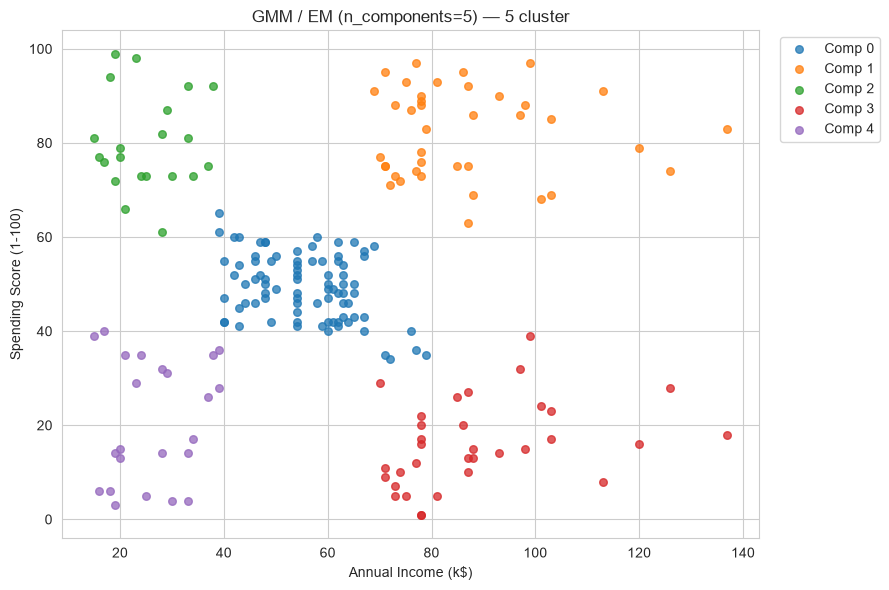

In [24]:
plt.figure(figsize=(9, 6))
for label in sorted(set(labels_gmm)):
    mask = labels_gmm == label
    plt.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                s=30, alpha=0.75, label=f"Comp {label}")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"GMM / EM (n_components=5) — {len(set(labels_gmm))} cluster")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

- Probabilitas keanggotaan: Untuk tiap titik, GMM menghasilkan probabilitas terhadap setiap komponen Gaussian. Nilai tinggi berarti yakin, nilai dekat merata berarti titik ambigu dan biasanya berada di perbatasan cluster.
- `n_components` berubah: Makin besar, model makin fleksibel dan BIC awalnya turun lalu bisa naik karena trade-off fit vs kompleksitas. Silhouette umumnya memuncak pada sekitar 5 komponen.
- Mengapa ditentukan di awal: GMM butuh jumlah komponen Gaussian untuk diestimasi parameternya. EM hanya mengoptimalkan parameter, bukan jumlah komponen.
- Silhouette vs BIC: Keduanya tidak selalu menunjuk nilai `n_components` yang sama. Silhouette mengukur pemisahan geometrik, BIC menyeimbangkan likelihood dengan kompleksitas model.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [25]:
def evaluate(X_scaled, labels, name):
    labels = np.asarray(labels)
    non_noise = labels != -1
    X_eval = X_scaled[non_noise]
    lbl_eval = labels[non_noise]
    n_c = len(set(lbl_eval))
    n_n = int((~non_noise).sum())
    if n_c < 2 or n_c >= len(lbl_eval):
        return {"model": name, "n_clusters": n_c, "n_noise": n_n,
                "silhouette": np.nan, "davies_bouldin": np.nan,
                "calinski_harabasz": np.nan}
    return {
        "model": name, "n_clusters": n_c, "n_noise": n_n,
        "silhouette": silhouette_score(X_eval, lbl_eval),
        "davies_bouldin": davies_bouldin_score(X_eval, lbl_eval),
        "calinski_harabasz": calinski_harabasz_score(X_eval, lbl_eval),
    }

In [26]:
summary = pd.DataFrame([
    evaluate(X_scaled, labels_dbscan, "DBSCAN (eps=0.3, ms=5)"),
    evaluate(X_scaled, labels_birch,  "BIRCH (thr=0.5, k=5)"),
    evaluate(X_scaled, labels_gmm,    "GMM (k=5)"),
])
summary

,model,n_clusters,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.3, ms=5)",7,35,0.524328,0.579955,185.575811
1,"BIRCH (thr=0.5, k=5)",5,0,0.414450,0.697938,125.948605
2,GMM (k=5),5,0,0.553689,0.576010,244.940197


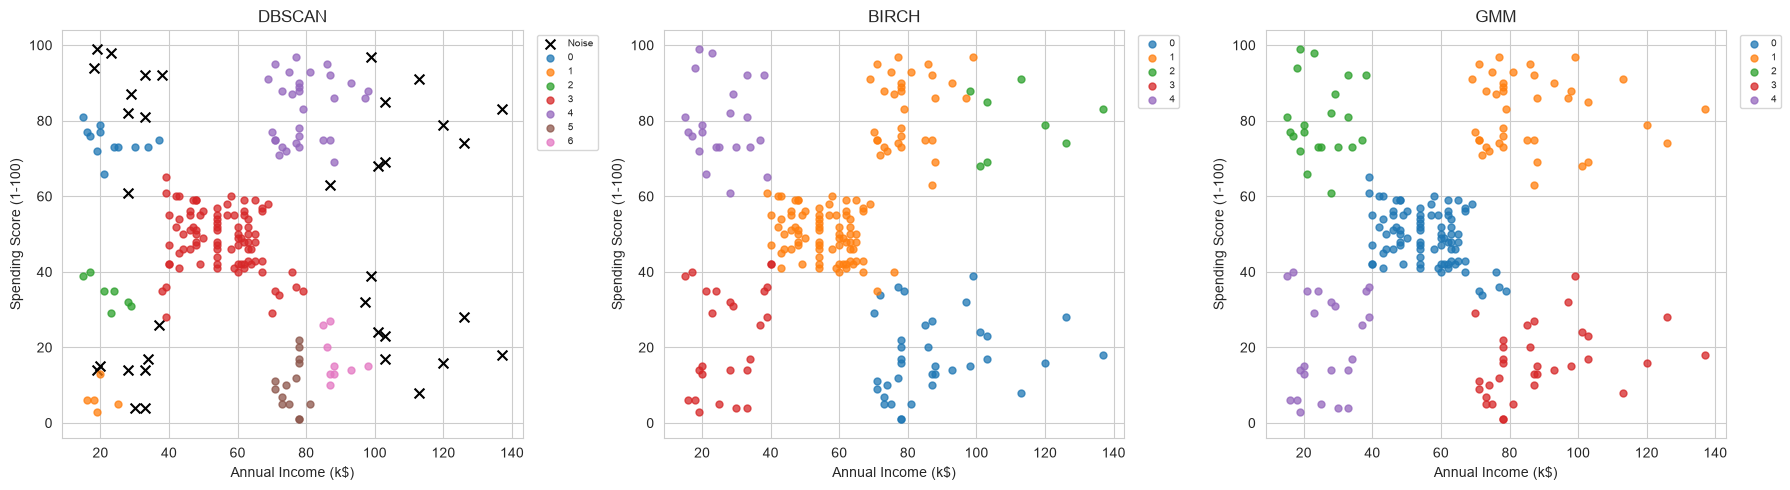

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, labels, title in zip(
        axes,
        [labels_dbscan, labels_birch, labels_gmm],
        ["DBSCAN", "BIRCH", "GMM"]):
    for label in sorted(set(labels)):
        mask = labels == label
        if label == -1:
            ax.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                    c="black", marker="x", s=50, label="Noise")
        else:
            ax.scatter(X.iloc[mask, 0], X.iloc[mask, 1],
                    s=25, alpha=0.75, label=f"{label}")
    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [29]:
def profile(X_orig, labels, name):
    d = X_orig.copy()
    d["cluster"] = labels
    return (d.groupby("cluster")
            .agg(n=("cluster", "size"),
                median_income=("Annual Income (k$)", "median"),
                mean_income=("Annual Income (k$)", "mean"),
                median_spending=("Spending Score (1-100)", "median"),
                mean_spending=("Spending Score (1-100)", "mean"))
            .round(2)
            .rename_axis(f"{name} cluster"))

print("DBSCAN:"); print(profile(X, labels_dbscan, "DBSCAN"))
print("\nBIRCH:");  print(profile(X, labels_birch,  "BIRCH"))
print("\nGMM:");    print(profile(X, labels_gmm,    "GMM"))

DBSCAN:
                 n  median_income  mean_income  median_spending  mean_spending
DBSCAN cluster                                                                
-1              35           87.0        70.60             61.0          51.66
 0              12           20.5        23.17             74.0          74.58
 1               5           19.0        19.60              6.0           6.60
 2               7           23.0        22.43             35.0          34.43
 3              88           54.0        55.23             49.0          48.58
 4              30           78.0        79.53             86.0          83.13
 5              14           77.5        75.93              9.5          10.07
 6               9           87.0        88.78             15.0          17.00

BIRCH:
                 n  median_income  mean_income  median_spending  mean_spending
BIRCH cluster                                                                 
0               36           83.0   

| Aspek | DBSCAN | BIRCH | EM / GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster awal | Tidak | Opsional (`n_clusters`) | Ya (`n_components`) |
| Label noise eksplisit | Ya (-1) | Tidak | Tidak |
| Parameter paling berpengaruh | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dimodelkan | Berbasis kepadatan (arbitrer) | Bola atau elipsoid ringkas (CF) | Elipsoid Gaussian |
| Kelebihan | Deteksi noise, tak perlu `k` | Cepat, skalabel | Probabilistik, cluster tumpang tindih |
| Kekurangan | Sensitif `eps` dan `min_samples` | Kurang cocok untuk bentuk non-konveks | Perlu `k`, asumsi Gaussian |

# 7. Analisis

1. Scaling diperlukan karena semua tiga algoritma bergantung pada jarak atau kovarians. Tanpa scaling, `Annual Income` dengan rentang yang lebih besar akan mendominasi `Spending Score`, padahal keduanya seharusnya setara.
2. Pada DBSCAN, memperbesar `eps` mengurangi cluster dan noise. Memperbesar `min_samples` menambah noise. Kombinasi ekstrem menghasilkan terlalu banyak noise atau satu cluster saja.
3. Pada BIRCH, memperbesar `threshold` cenderung mengurangi jumlah cluster karena lebih banyak penggabungan. Menetapkan `n_clusters` memaksa jumlah akhir. Titik jauh tidak dibuang sebagai noise, tetapi tetap dimasukkan ke cluster terdekat.
4. Probabilitas keanggotaan GMM menunjukkan seberapa besar keyakinan titik milik tiap komponen. EM bergantian menghitung ekspektasi keanggotaan (E-step) dan memperbarui parameter Gaussian (M-step) hingga konvergen.
5. GMM paling mudah diinterpretasikan karena memberi probabilitas dan label per komponen yang sangat konsisten dengan lima kelompok visual. BIRCH juga mudah dibaca sebagai partisi keras. DBSCAN sedikit lebih sulit karena ada label noise.
6. Metrik tidak selalu sepakat. Silhouette memuncak di sekitar 5 cluster untuk GMM dan BIRCH, tetapi BIC terus turun seiring `n_components`. Penyebabnya adalah Silhouette mengukur pemisahan geometrik, sedangkan BIC menyeimbangkan likelihood dengan kompleksitas.
7. Karakteristik cluster berdasarkan median menunjukkan lima segmen khas: low income low spending (hemat), low income high spending (impulsif), mid income mid spending (standar), high income low spending (konservatif), dan high income high spending (target premium).
8. Keterbatasan penggunaan hanya dua fitur adalah `Age` dan `Gender` tidak diperhitungkan sehingga segmen kurang kaya. Dataset kecil (200 baris) membuat hasil sensitif terhadap parameter dan mudah over-fit.

# 8. Kesimpulan dan Saran

- Algoritma paling berguna: GMM dengan `n_components=5` dan BIRCH dengan `n_clusters=5` memberi hasil paling stabil dan mudah diinterpretasikan. DBSCAN berguna bila ingin mendeteksi pelanggan yang tidak biasa atau noise.
- Parameter yang dipilih: DBSCAN `eps=0.3` dan `min_samples=5`, BIRCH `threshold=0.5` dan `n_clusters=5`, serta GMM `n_components=5` dan `covariance_type='full'`.
- Perbedaan utama: DBSCAN berbasis kepadatan dan tanpa `k`. BIRCH berbasis hierarki ringkasan dan cepat. EM GMM bersifat probabilistik dan memberi keanggotaan lunak.
- Eksperimen lanjutan: Tambahkan `Age` atau `Gender` (one-hot) sebagai fitur, bandingkan dengan K-Means, gunakan tuning parameter otomatis, atau mencoba `covariance_type` lain seperti `diag` dan `tied` pada GMM.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)